# P02 — CellBender: segunda opinião sobre células e RNA ambiente

O CellBender `remove-background` é a alternativa em Python para separar
gotas com célula de gotas vazias. Em vez de testar cada barcode contra o
perfil ambiente, como o emptyDrops, ele ajusta um modelo generativo da
matriz raw inteira: cada gota tem uma probabilidade de conter célula, e as
contagens de cada gota são decompostas em RNA da célula e RNA ambiente.

O treino (150 épocas, GPU, `--expected-cells` = chamada do Cell Ranger,
`--fpr 0.01`) rodou fora deste notebook, por `raw/run_cellbender.py`. As
saídas ficam em `HEAVY_OUT/cellbender/<biblioteca>/`. Aqui só se leem.

Perguntas: o treino convergiu? Que barcodes o CellBender chama, e como isso
se compara com o Cell Ranger e com o emptyDrops (P01)? Quanto de RNA
ambiente ele estima e remove?

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

from functions import bpqc, config, droplets, fmt as F, io, plotting, qcplots
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "P02_cellbender"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
PROB = config.CELLBENDER_PROB
PAINEIS = {"T": config.MARKERS_T, "B": config.MARKERS_B, "mieloide": config.MARKERS_MYELOID,
           "eritroide": config.MARKERS_ERYTHROID, "plaqueta": ["PPBP", "PF4", "GP9", "ITGA2B", "TUBB1"]}

faltando = [l for l in LIBS if not droplets.cellbender_done(l)]
assert not faltando, f"CellBender ainda não terminou: {faltando}"

## 1. Convergência

In [2]:
curvas, linhas = {}, []
for lib in LIBS:
    with h5py.File(droplets.cellbender_dir(lib) / "output.h5", "r") as f:
        tr = f["metadata/learning_curve_train_elbo"][()]
        te = f["metadata/learning_curve_test_elbo"][()]
        te_ep = f["metadata/learning_curve_test_epoch"][()]
        n_drop = len(f["metadata/barcodes_analyzed"][()])
    curvas[lib] = (tr, te, te_ep)
    ult = tr[-10:]
    linhas.append({"library_id": lib, "epocas": len(tr), "gotas_analisadas": n_drop,
                   "elbo_treino_final": float(tr[-1]), "elbo_teste_final": float(te[-1]) if len(te) else np.nan,
                   "variacao_ultimas_10_epocas": float((ult.max() - ult.min()) / abs(ult.mean()))})
conv = pd.DataFrame(linhas).set_index("library_id")
io.save_table(conv, NB, "convergencia", description="Curva de aprendizado do CellBender por biblioteca")
conv.round(4)

,epocas,gotas_analisadas,elbo_treino_final,elbo_teste_final,variacao_ultimas_10_epocas
library_id,,,,,
CTH92_NS,150,20851,-619.6150,-661.1600,0.0785
CTH92_ML,150,21570,-589.3101,-619.2705,0.0096
CTH94_NS,150,26090,-2670.7578,-2671.3905,0.0632
CTH94_ML,150,20547,-613.3465,-843.8762,0.1084
CTH97_NS,150,29638,-754.8689,-704.7245,0.0519
CTH97_ML,150,24737,-755.1700,-763.4307,0.0114
PB20_NS,150,4000,-1284.3032,-1713.5109,0.0412
PB20_ML,150,20841,-747.1755,-755.0909,0.0655
PB21_NS,150,47586,-1582.9007,-1636.1179,0.0400


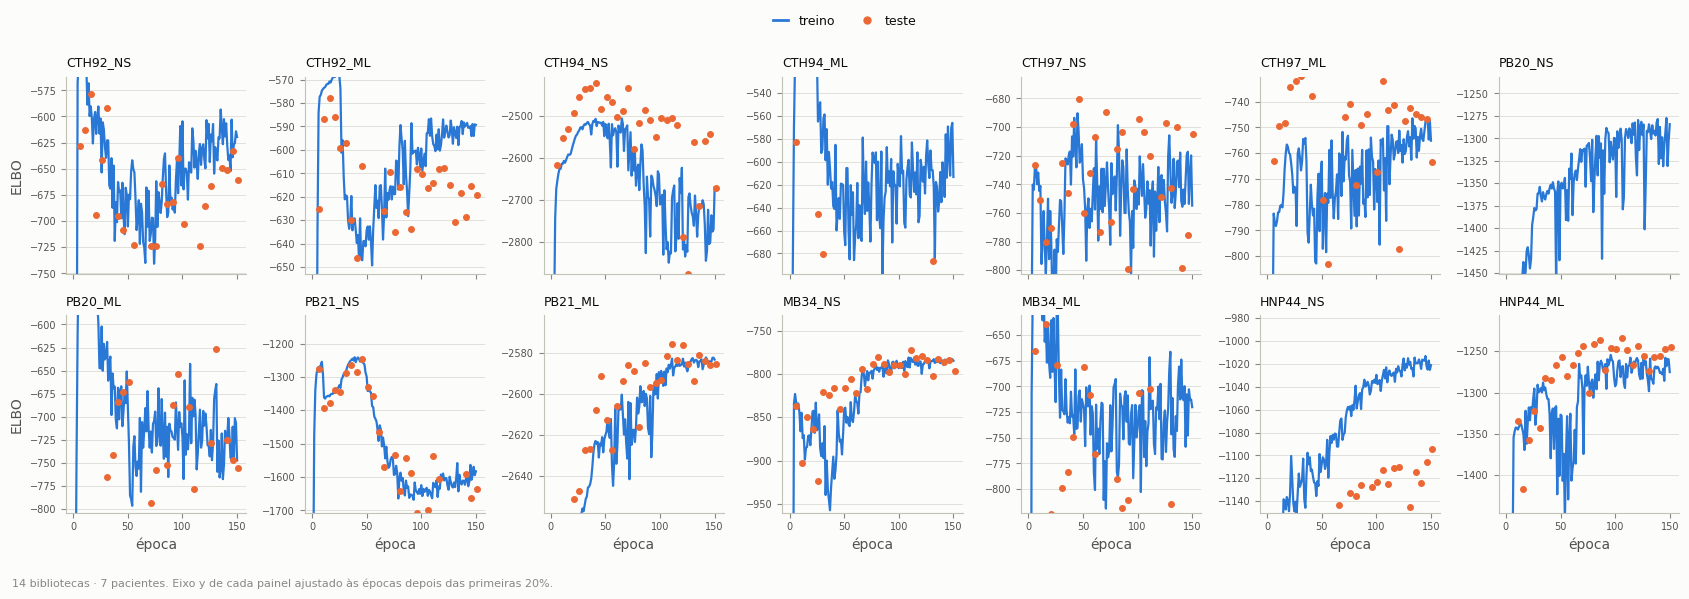

In [3]:
fig, axes = plt.subplots(2, 7, figsize=(17, 5.6), sharex=True)
for ax, lib in zip(axes.ravel(), LIBS):
    tr, te, te_ep = curvas[lib]
    ax.plot(np.arange(1, len(tr) + 1), tr, color=plotting.CATEGORICAL[0], lw=1.6, label="treino")
    if len(te):
        ax.plot(te_ep + 1, te, "o", ms=4, color=plotting.CATEGORICAL[1], label="teste")
    ax.set_title(lib, fontsize=9, fontweight="normal")
    lo = np.percentile(tr[len(tr) // 5:], 1)
    hi = np.percentile(tr[len(tr) // 5:], 99)
    ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.3 * (hi - lo))
    ax.tick_params(labelsize=7)
for ax in axes[1]:
    ax.set_xlabel("época")
for ax in axes[:, 0]:
    ax.set_ylabel("ELBO")
fig.legend(handles=[mpl.lines.Line2D([], [], color=plotting.CATEGORICAL[0], lw=2, label="treino"),
                    mpl.lines.Line2D([], [], marker="o", ls="", ms=5, color=plotting.CATEGORICAL[1], label="teste")],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
plotting.note(fig, f"{plotting.N_DESIGN}. Eixo y de cada painel ajustado às épocas depois das primeiras 20%.", y=0.0)
fig.tight_layout(rect=(0, 0.02, 1, 0.96))
plotting.savefig(fig, NB, "convergencia", description="ELBO de treino e teste do CellBender por biblioteca",
                 data=conv.reset_index(), data_index=False)
plt.show()

## 2. Quem é célula para cada método

Três chamadas sobre os mesmos barcodes: Cell Ranger (matriz filtrada),
emptyDrops (FDR ≤ 0,001, P01) e CellBender (probabilidade de célula > 0,5).

In [4]:
cand = io.load_data("P01_gotas_vazias", "candidatos")
mb = io.load_data("C03_rarefacao_citocinas", "mol_barcodes")
mb = mb.set_index(mb["library_id"] + "|" + mb["barcode"])["frac_intronica"]

partes, amb, metr = [], {}, []
for lib in LIBS:
    cb = droplets.read_cellbender(lib)
    amb[lib] = cb["ambient"]
    metr.append(cb["metrics"].rename(lib))
    prob = cb["prob"]
    c = cand[cand["library_id"] == lib].set_index("barcode")
    todos = c.index.union(prob.index[prob > PROB])
    d = pd.DataFrame(index=todos)
    d["library_id"] = lib
    d["cellbender_prob"] = prob.reindex(todos).to_numpy()
    d["cellbender"] = d["cellbender_prob"] > PROB
    for col in ("cellranger", "emptydrops"):
        d[col] = c[col].reindex(todos).fillna(False).astype(bool).to_numpy()
    partes.append(d.rename_axis("barcode").reset_index())
chamadas = pd.concat(partes, ignore_index=True)
metr = pd.concat(metr, axis=1).T

sets = ["cellranger", "emptydrops", "cellbender"]
combo = chamadas[sets].astype(int).astype(str).agg("".join, axis=1)
nomes_combo = {"100": "só Cell Ranger", "010": "só emptyDrops", "001": "só CellBender", "110": "CR + emptyDrops",
               "101": "CR + CellBender", "011": "emptyDrops + CellBender", "111": "os três"}
chamadas["combinacao"] = combo.map(nomes_combo)
tab_combo = pd.crosstab(chamadas["library_id"], chamadas["combinacao"]).reindex(LIBS).fillna(0).astype(int)
tab_combo = tab_combo[[c for c in nomes_combo.values() if c in tab_combo.columns]]
por_lib = pd.DataFrame({
    "Cell Ranger": chamadas.groupby("library_id")["cellranger"].sum(),
    "emptyDrops": chamadas.groupby("library_id")["emptydrops"].sum(),
    "CellBender": chamadas.groupby("library_id")["cellbender"].sum(),
    "CellBender e não Cell Ranger": (chamadas["cellbender"] & ~chamadas["cellranger"]).groupby(chamadas["library_id"]).sum(),
    "Cell Ranger e não CellBender": (chamadas["cellranger"] & ~chamadas["cellbender"]).groupby(chamadas["library_id"]).sum(),
    "fração de contagens removida": pd.to_numeric(metr["fraction_counts_removed_from_cells"]),
}).reindex(LIBS)
io.save_table(tab_combo, NB, "combinacoes_de_chamadas", description="Barcodes por combinação de métodos que os chamam")
io.save_table(por_lib, NB, "chamadas_por_biblioteca", description="Células por método e por biblioteca; fração removida pelo CellBender")
display(tab_combo)
por_lib

combinacao,só emptyDrops,só CellBender,CR + emptyDrops,CR + CellBender,emptyDrops + CellBender,os três
library_id,,,,,,
CTH92_NS,66,17,0,24,23,827
CTH92_ML,57,167,0,12,49,1558
CTH94_NS,556,1104,0,146,53,5944
CTH94_ML,90,120,2,7,15,538
CTH97_NS,5060,7,0,15,56,1613
CTH97_ML,158,432,0,365,336,4372
PB20_NS,86,49,0,54,0,581
PB20_ML,77,14,0,25,49,816
PB21_NS,2984,180,3,42,18404,4221


,Cell Ranger,emptyDrops,CellBender,CellBender e não Cell Ranger,Cell Ranger e não CellBender,fração de contagens removida
CTH92_NS,851,916,891,40,0,0.012
CTH92_ML,1570,1664,1786,216,0,0.014
CTH94_NS,6090,6553,7247,1157,0,0.016
CTH94_ML,547,645,680,135,2,0.012
CTH97_NS,1628,6729,1691,63,0,0.012
CTH97_ML,4737,4866,5505,768,0,0.013
PB20_NS,635,667,684,49,0,0.013
PB20_ML,841,942,904,63,0,0.011
PB21_NS,4266,25612,22847,18584,3,0.019
PB21_ML,11374,12251,11694,331,11,0.012


## 3. Métricas dos barcodes que só o CellBender chama

Os barcodes chamados só pelo CellBender não estavam na tabela de P01;
as mesmas métricas são calculadas aqui, para que P03 trate todos os
candidatos do mesmo jeito.

In [5]:
novos = []
for lib in LIBS:
    falta = chamadas[(chamadas["library_id"] == lib) & ~chamadas["barcode"].isin(cand.loc[cand["library_id"] == lib, "barcode"])]
    if falta.empty:
        continue
    raw = io.read_raw(lib)
    pos = pd.Index(raw["barcodes"]).get_indexer(falta["barcode"])
    X = raw["X"][pos]
    nomes = raw["gene_names"]
    mt = np.char.startswith(nomes.astype(str), "MT-")
    umis = np.asarray(X.sum(axis=1)).ravel()
    df = pd.DataFrame({"library_id": lib, "barcode": falta["barcode"].to_numpy(), "umis": umis,
                       "genes": np.asarray((X > 0).sum(axis=1)).ravel(),
                       "pct_mt": np.asarray(X[:, mt].sum(axis=1)).ravel() / np.maximum(umis, 1) * 100})
    ls = bpqc.lineage_scores(X, nomes, PAINEIS)
    for k in PAINEIS:
        df[f"frac_{k}"] = ls[k].to_numpy()
    novos.append(df)
    del raw, X
novos = pd.concat(novos, ignore_index=True) if novos else pd.DataFrame(columns=["library_id", "barcode"])
cols_cand = ["library_id", "barcode", "umis", "genes", "pct_mt"] + [f"frac_{k}" for k in PAINEIS]
metricas = pd.concat([cand[cols_cand + ["llr", "limiar_llr", "parece_celula"]], novos[cols_cand]], ignore_index=True)
todos = chamadas.merge(metricas, on=["library_id", "barcode"], how="left")
todos["frac_intronica"] = mb.reindex(todos["library_id"] + "|" + todos["barcode"]).to_numpy()
assert todos["umis"].notna().all()
print(f"{F.n(len(todos))} barcodes candidatos; {F.n(len(novos))} chamados só pelo CellBender e acrescentados agora; "
      f"fração intrônica ausente em {int(todos['frac_intronica'].isna().sum())} (barcodes com < 50 moléculas)")

88.154 barcodes candidatos; 154 chamados só pelo CellBender e acrescentados agora; fração intrônica ausente em 55 (barcodes com < 50 moléculas)


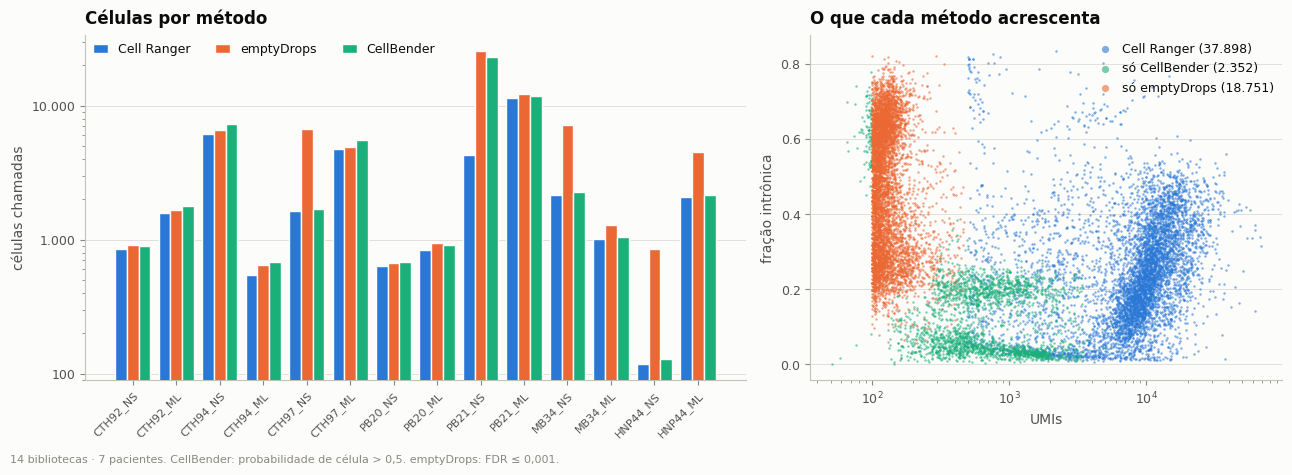

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
x = np.arange(len(LIBS))
w = 0.27
for i, (nome, cor) in enumerate([("Cell Ranger", plotting.CATEGORICAL[0]), ("emptyDrops", plotting.CATEGORICAL[1]),
                                 ("CellBender", plotting.CATEGORICAL[2])]):
    axes[0].bar(x + (i - 1) * w, por_lib[nome], width=w, color=cor, edgecolor=INK["surface"], linewidth=1, label=nome, zorder=3)
axes[0].set_yscale("log")
axes[0].set_xticks(x)
axes[0].set_xticklabels(LIBS, rotation=45, ha="right", rotation_mode="anchor", fontsize=8)
axes[0].yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.n(v)))
axes[0].set_ylabel("células chamadas")
axes[0].set_title("Células por método")
axes[0].legend(loc="upper left", ncol=3)
axes[0].grid(axis="x", visible=False)
sub = todos[todos["frac_intronica"].notna()]
for nome, m, cor in [("Cell Ranger", sub["cellranger"], plotting.CATEGORICAL[0]),
                     ("só CellBender", sub["cellbender"] & ~sub["cellranger"] & ~sub["emptydrops"], plotting.CATEGORICAL[2]),
                     ("só emptyDrops", sub["emptydrops"] & ~sub["cellranger"] & ~sub["cellbender"], plotting.CATEGORICAL[1])]:
    d = sub[m]
    if len(d) > 6000:
        d = d.sample(6000, random_state=0)
    axes[1].scatter(d["umis"], d["frac_intronica"], s=3, lw=0, alpha=0.6, color=cor, rasterized=True, label=f"{nome} ({F.n(m.sum())})")
axes[1].set_xscale("log")
axes[1].set_xlabel("UMIs")
axes[1].set_ylabel("fração intrônica")
axes[1].set_title("O que cada método acrescenta")
axes[1].legend(loc="upper right", markerscale=3)
plotting.note(fig, f"{plotting.N_DESIGN}. CellBender: probabilidade de célula > 0,5. emptyDrops: FDR ≤ 0,001.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "chamadas_por_metodo", description="Células chamadas por Cell Ranger, emptyDrops e CellBender",
                 data=por_lib.reset_index(), data_index=False)
plt.show()

## 4. RNA ambiente segundo o CellBender

In [7]:
amb_df = pd.DataFrame(amb)
sym = io.reference_features().set_index("gene_id")["gene_name"]
top_amb = {lib: ", ".join(sym.reindex(amb_df[lib].nlargest(8).index).fillna("?")) for lib in LIBS}
amb_tab = pd.DataFrame({"fração de contagens removida das células": por_lib["fração de contagens removida"],
                        "genes mais abundantes no ambiente": pd.Series(top_amb)}).reindex(LIBS)
io.save_table(amb_tab, NB, "ambiente_cellbender", description="RNA ambiente estimado pelo CellBender por biblioteca")
io.save_data(amb_df.rename_axis("gene_id").reset_index(), NB, "perfil_ambiente_cellbender",
             description="Perfil de expressão ambiente estimado pelo CellBender, por biblioteca")
with pd.option_context("display.max_colwidth", None):
    display(amb_tab)

[io] inalterado, não regravado: perfil_ambiente_cellbender.parquet


,fração de contagens removida das células,genes mais abundantes no ambiente
CTH92_NS,0.012,"RPS27, RPL10, RPL41, RPL13, RPL28, RPS12, RPL32, RPLP1"
CTH92_ML,0.014,"RPS27, RPL10, RPL41, RPL13, RPL28, RPS12, FTH1, RPL32"
CTH94_NS,0.016,"MALAT1, B2M, EEF1A1, TPT1, TMSB4X, RPS27, RPS12, RPL10"
CTH94_ML,0.012,"RPS27, RPL10, RPL41, RPL13, RPL28, RPS12, FTH1, RPLP1"
CTH97_NS,0.012,"SLC26A3, STEAP1B, FOXP1, GPM6A, RPS27, RPL13, RPL41, RPS12"
CTH97_ML,0.013,"B2M, RPS27, RPS12, RPL41, RPL13, TPT1, RPLP1, RPL10"
PB20_NS,0.013,"SLC26A3, RPS27, MALAT1, FTH1, FOXP1, RPL13, RPL41, RPS12"
PB20_ML,0.011,"RPS27, RPL13, RPL41, FTH1, RPL10, RPS12, TPT1, B2M"
PB21_NS,0.019,"RPS27, SLC26A3, RPL13, RPS12, RPL41, RPL28, RPL32, RPL10"
PB21_ML,0.012,"MALAT1, RPS27, RPS12, RPL41, RPLP1, B2M, RPL13, TPT1"


In [8]:
io.save_data(todos, NB, "candidatos_todos",
             description="Barcodes chamados por Cell Ranger, emptyDrops ou CellBender, com métricas")

[io] conteúdo mudou — nova versão: candidatos_todos__v2.parquet (anterior preservada)


PosixPath('/mnt/SATA/singleCellTaru/dataReseq/P02_cellbender/candidatos_todos__v2.parquet')

## Problemas encontrados

In [9]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       0
MINOR       0
INFO        0


severity,location,problem,evidence,impact,recommendation


## Conclusão

O CellBender convergiu nas 14 bibliotecas (ELBO estável nas últimas
épocas; PB20_NS e HNP44_NS precisaram de menos gotas analisadas). Ele chama
praticamente todas as células do Cell Ranger e acrescenta de 11 (HNP44_NS) a
1.157 (CTH94_NS) barcodes — e 18.584 em PB21_NS, onde, como o emptyDrops,
toma o material nuclear de células mortas por célula. A fração das contagens
que ele atribui ao RNA ambiente fica entre 0,9% e 1,9%. Os barcodes que ele
acrescenta passam pelo mesmo QC em P03.

In [10]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

11 artefatos gravados por este notebook:
                      name    kind
perfil_ambiente_cellbender parquet
              convergencia   table
          fig_convergencia  figure
          fig_convergencia   table
   combinacoes_de_chamadas   table
   chamadas_por_biblioteca   table
   fig_chamadas_por_metodo  figure
   fig_chamadas_por_metodo   table
       ambiente_cellbender   table
          candidatos_todos parquet
                    issues   table
